# Comparing Different Search Strategies: Maze

Notes on breaking ties: 

* The order in which the children are explored (see `available directions`) makes a big difference for DFS and dealing with empty spaces. I explore the directions in random order which makes the algorithm stochastic!
* Ties for $h(n)$ and $f(n)$ need to be broken in a consistent manner. I use the most recently added node. To try to keep moving into the same direction.



Helper functions for the Maze Assignment by M. Hahsler
Usage: 
  import maze_helper as mh
  mh.show_some_mazes()
  
Here is an example maze:

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX

The goal is at (np.int64(8), np.int64(1)).
Position(0,0): X
Position(8,1):  


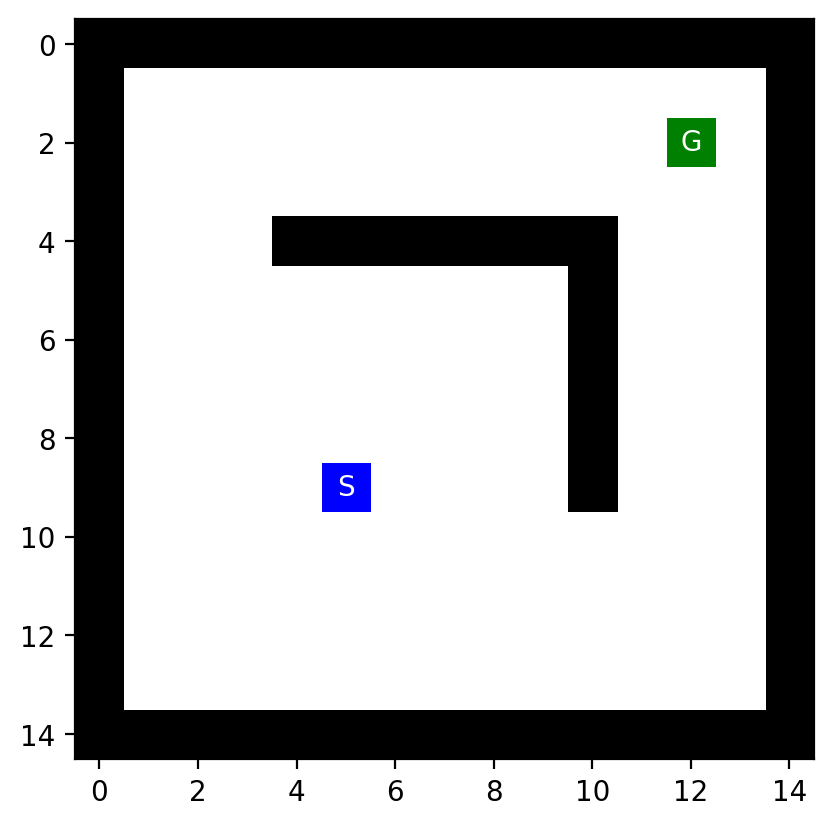

In [1]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np

#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

# look at two positions in the maze
print("Position(0,0):", maze[0, 0])
print("Position(8,1):", maze[8, 1])

show_maze(maze)

## Implementation

My implementation follows the pseudo code from the slides/textbook.

In [2]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

## Experiments

### BFS

CPU times: user 704 μs, sys: 78 μs, total: 782 μs
Wall time: 786 μs
Path cost: 16 | Expanded: 151 | Max frontier: 17 | Max depth: 16
Actions: EEEESEENNNNNNNNE


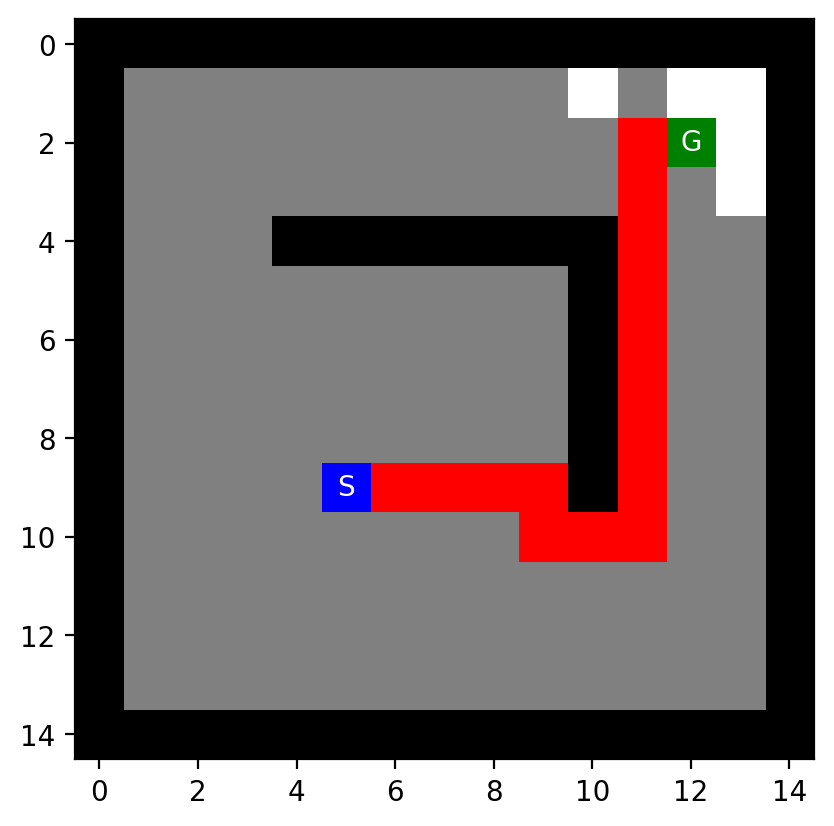

['E',
 'E',
 'E',
 'E',
 'S',
 'E',
 'E',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'E']

In [3]:
ts.set_order("NESW")
#ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "BFS", debug = False, vis = False)
ts.show_path(maze, result)
result['actions']

### DFS 

This implementation uses not reached data structure and has space complexity $O(bm)$ instead of $O(b^m)$ when we reuse the tree search algorithm from BFS!

We need to check for all cycles. If we do not break all cycles correctly, then we will end up in an infinite loop. Here are possible solutions:
* Stop after a fixed number of tries and return no solution `max_tries`.
* IDS solves this problem.

Note on the visualization: I use gray for areas that the algorithm has explored, but DFS has already removed it from memory!

CPU times: user 1.78 ms, sys: 0 ns, total: 1.78 ms
Wall time: 1.79 ms
Path cost: 122 | Expanded: 132 | Max frontier: 109 | Max depth: 121
Actions: WWWWSSSSEEEEEEEEEEEENWWWWWWWWWWWNEEEEEEEEEEENWWWWWWWNEEENWWWWWWWWNEEEEEEEENWWWWWWWWNEENWWNEEEEEEEEEESSSSSSEENWNENWNENWNENW


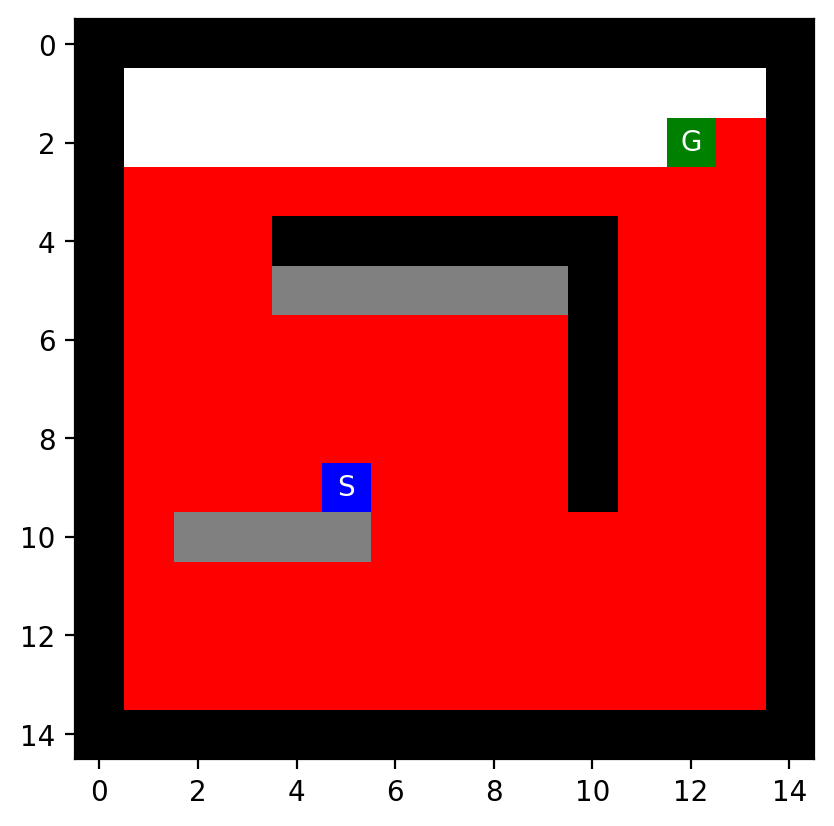

In [4]:
# Note: DFS uses LIFO so the directions come from the stack in reverse order!

# Can get stuck for empty maze since cycle checking is not string enough! 
# I use a maximum number of tries and stop if the goal is not reached.
ts.set_order("NESW")
#ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

Do the same, but change the order in which we explore states (add them to them as nodes to the frontier).

CPU times: user 277 μs, sys: 31 μs, total: 308 μs
Wall time: 310 μs
Path cost: 26 | Expanded: 26 | Max frontier: 30 | Max depth: 25
Actions: WWWWNNNNNNNNEEEEEEEEEEEESW


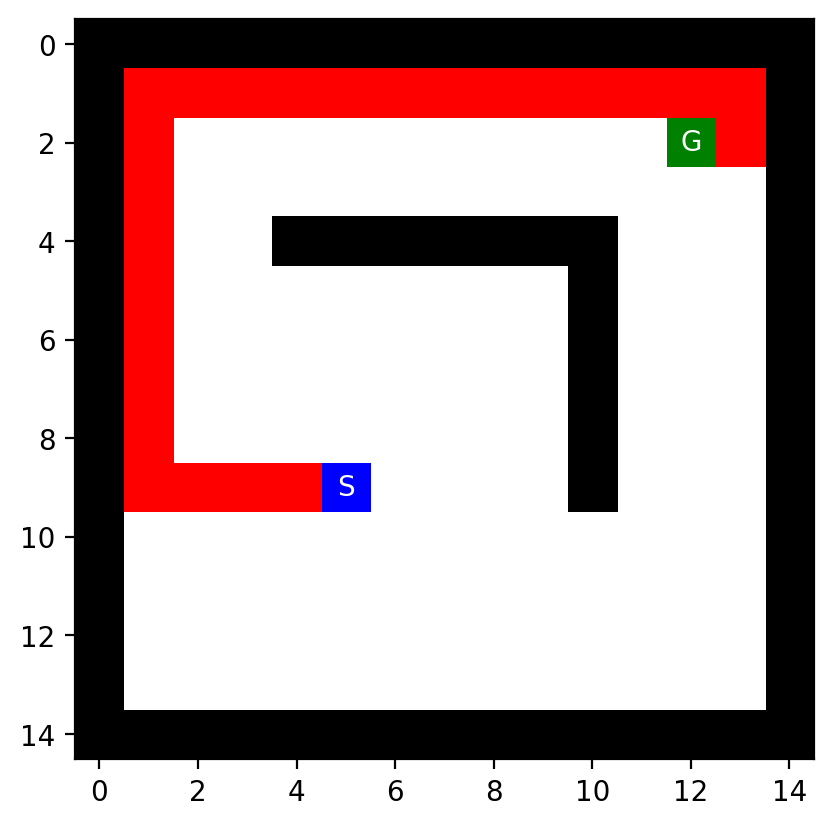

In [5]:
#ts.set_order("NESW")
ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

We could do a random walk and not check for cycles. This is guaranteed to reach eventually any square including the goal, 
but creates a long path. The path could be simplified leading to the [Tremaux's algorithm](https://en.wikipedia.org/wiki/Maze_solving_algorithm).

CPU times: user 1.01 ms, sys: 113 μs, total: 1.12 ms
Wall time: 1.13 ms
Path cost: 128 | Expanded: 128 | Max frontier: 335 | Max depth: 127
Actions: SNEWNNESSEWNSWNNSWEWWNNSSNENSSESWEEWWNNNNWWEESWNNNNWWNEWESENSESNWEEESNNEWSSENNEEWSWWSEWEWWNWSENNWSWENEEESSNNEWESNEWSEEESNNSNEESW


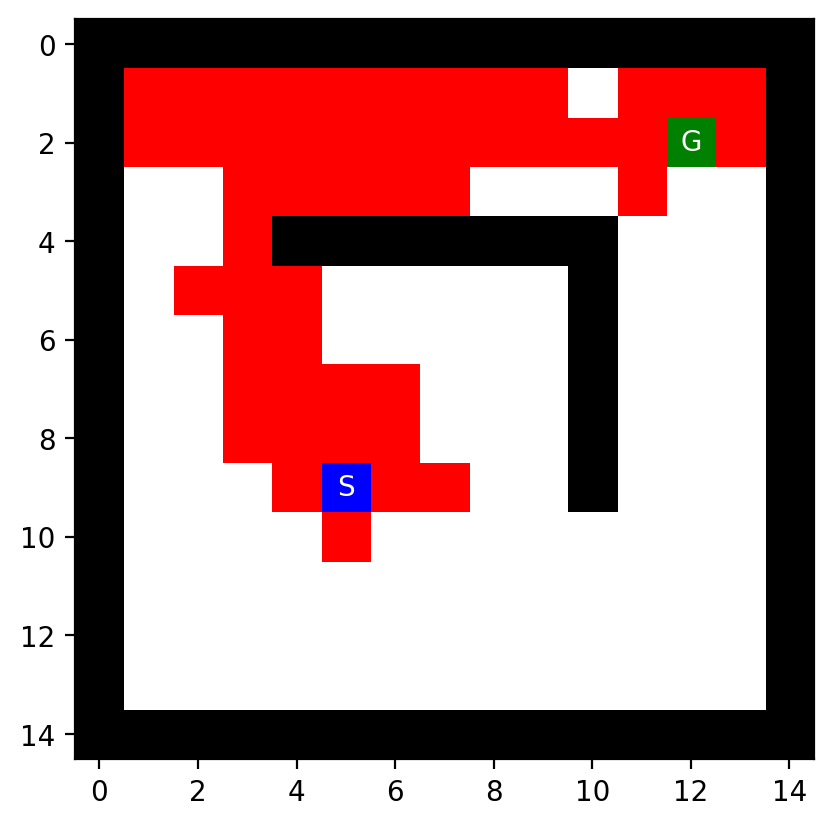

CPU times: user 18.6 ms, sys: 0 ns, total: 18.6 ms
Wall time: 18.4 ms
Path cost: 1620 | Expanded: 1620 | Max frontier: 4296 | Max depth: 1619
Actions: WEEWWEWNWSWWSSEWSESNWNSENSSWENEWSENESEWWNNEWENNEEEWSESNNSENNEWSWWNSNESEWNSSSWSESEWWWNNWESSNNNEESESSWNESWEEENNEENSWNSWWNESNSSNWENSNEWSWNWEEEESWEESSNNNWSEWEWWESEWNSENSWESWNSEWWWNWEEEEWENSWESNWWSEENWSWNWSWWNNWWWWENNEWEWSEESWNSNWEENSSSWNWSNESNEESSWWNEENSWNNNNSNWENNNSEENSSWNNEWEWWWEWEWWSSESNWNSENWESWESESEWWSSWWENEWNSWWWWENNNSNNNSWSEWEENSWSWEWNESSENSNSNWWSNEWSSEWNSSNEEWEEEWESWSNSSEEEENSWENNWENSEWNSWWSEENNSNSENESWNWENNNWSNNNEWWEWSNWSSESSEWSNNWEWSWWEENWEWEWWSWNSEWWWNESSWSSESNNESWEWSEWNSWEWNEEWSENEWENSSEWWNNNWEEEEESEWNNEWENNNEWNEWESWWWWWNEEEEWWWEWSWWEEENEEWWEWWESWWNSSEESSWWEWEENSNSWSSNNWEWENWEWWSNNSENWENWEEEWSSWENSWSENENNSSNEEESSSEEEENNSSNSWESNNSNNSSNSWESSWENSSWWENESNWESNNNSSWESNSWWEEWENNWEWEWENNSSNSWENSNWWEWWWSWWNENNSSEWNNEWWNESNEWESSNNWESSSNWSNENNSNNSNWWEWNSSEESWESSWSWNSWSSNWNNSNSSWWSWWEWENNNESNSEENWSEWENEEENENNSWWNEENWWEENSWESSNNWSENNWESWSSNNE

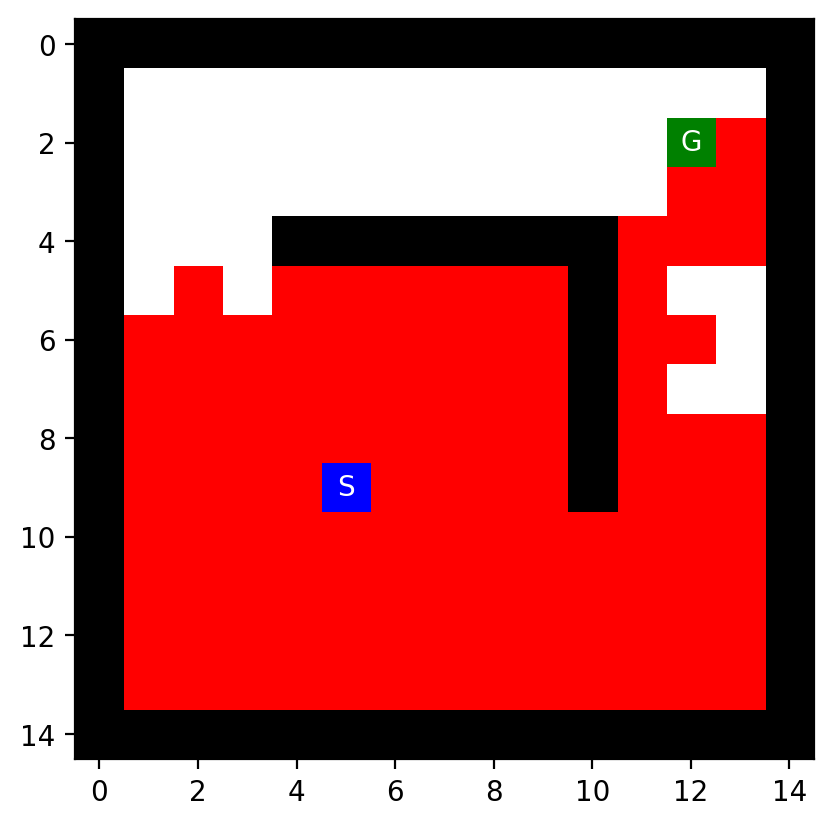

CPU times: user 5.89 ms, sys: 0 ns, total: 5.89 ms
Wall time: 5.86 ms
Path cost: 692 | Expanded: 692 | Max frontier: 1834 | Max depth: 691
Actions: WENWWEEESSWSESEWSWNWSNWSNSWWENWNSSEWNEEEWWSENWESNSWNWSEWNSEEWWENNNWSESSWEWNESENNWWNENNEENNWSWNNNSNSNNNEEEWWEEEEEWSNWEWSNNWSWNWEWWESEESWNENWSWSWWEESSWWSSSNENNNNSSNNSESSEWWENSWNESSEENESWWSWNEWNNSESWWENNSSESESESEESSNWSWESNSNWWWEWWWEWENNWNWNSNENNNWNSNEESESNWSSSESSSNNNWESWNNENSWSSSSENNWWENWWEEWSWENSSWSNESWSSNNNEEESNSEENNSSWWEWSESNNENSNNNWSSNWNSNSWNSSSWEWNWSNSSSEWEWEEEEWWNESENEEWEWNNSSWSEWWNNESWSWWWEEEWNEWNNNWSSNWNSENWEEEENENWSWESNEEWWSNESENSWNESENENNSNNWWEESSWSWSNEWESNWWNEWWEEWEEEWENWWNSNEWESWNEEWESWNEWESWWWSEWNWWNSSNWWWESESNNSNNNWSWESNSNSWNESENESEESWSENSNNSSENNWEENWSENWSWWNSNSWNWEWEWNWNEEWSNNEEEWESNESWENNSSWNNWSSNESNSNWENWSNWEWSSEEENWEWEEWWNSSNESEWNEWNEEWWSNSSNNWSNSEWESWEEEWNESNNSNEESNES


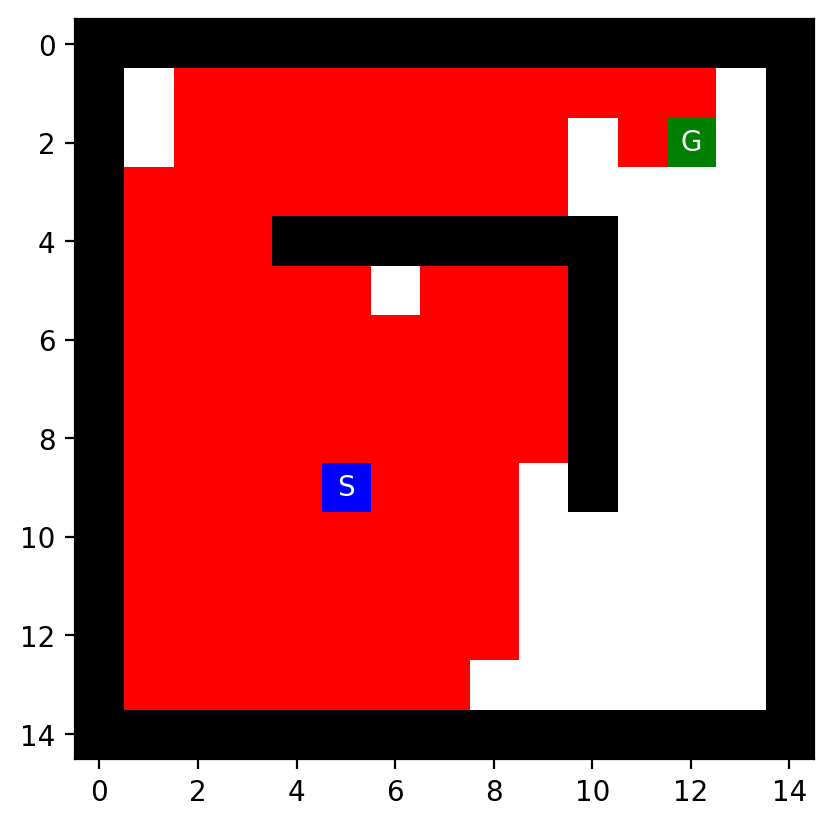

CPU times: user 1.6 ms, sys: 0 ns, total: 1.6 ms
Wall time: 1.61 ms
Path cost: 180 | Expanded: 180 | Max frontier: 487 | Max depth: 179
Actions: NESWNNWWSNSSENEEEEWENNNSEWWESESWSWSNWWWEWSSWWESENSEWENWWSWEEEWSENSEEEWWENENSNNWWENNEWSSENSEWSEEENNSEWEWSENWEWNNNESENWSEWWNSSSNNNESEWWEESWENSWWSENNEWNENSNNWENWWESNWEWNWWWWEEEENSSENN


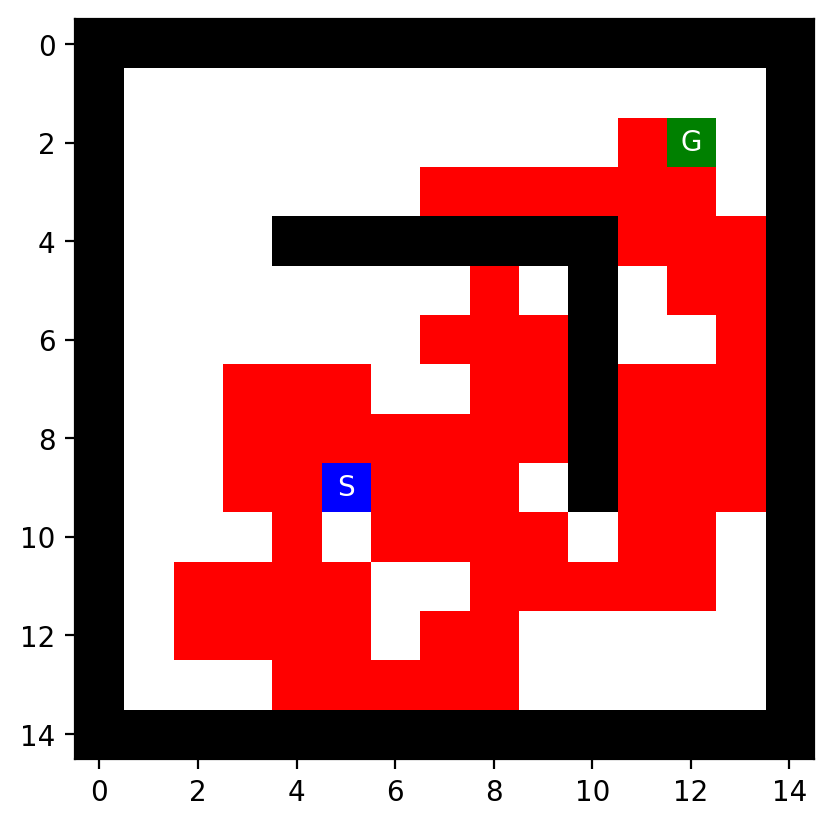

CPU times: user 19.3 ms, sys: 0 ns, total: 19.3 ms
Wall time: 19.1 ms
Path cost: 2614 | Expanded: 2614 | Max frontier: 6998 | Max depth: 2613
Actions: SEEENSEWWEWWEWNSNSENEENWESWESNWENWNSSENNSNSSWWSWEEESENWWSWNWESESSNNNNWSWSWNNWWWSSWSEWESWNEENNNNSNESSNESSESSEEWNEEWWENENNNSNSSNWEWNSWSNWSEWNWWSNNWWEENWSWSWEEEEWWWSSWSESEEWNWSNEWSENWWENWEEENSWWNNEEWNNENEEEESESSNNNSWWNNSESNESWWEWNEEWNEWESSSWWENSNSSWWWNSWWESWENNEEWEWEWNWWNSSWWEWESSEEWNWSESSSEENSEWNESNNSESNEWNWNNNNWWWNNWEWENSEWWNSSNNENSNNNWSWNSNSSNENEWESENWSSSNNNWWEEWSSSESEEEWSEEWNEESWEENSSSWEWEWWWEENESNNWSWNNSSWNSWNSSNSWSENEWNWNWWSENEENWEEWEEWSWNESEWNEWSSSNWNNSESWNNSWEWWWNSEWWENSNNENWWSNNNEWEWSSESSNNEENNWWSEWWSSSEENWEWEWENSSNWSWNNNNESWNESNWSSSEWSNEESWSNNSESNEEEWWWEEWEWWSSEESSEEEEWSNNNWSSNNWSWNSNSENNEWNSWWSSSNNEEWENESSSWNSESEWSESWEEESNNNWNWWSNWEWEEESSSNSSWENSWEEWENESWNSNNWWSWENWSENESNNNNWSNSNWWNSNESNWSWSNWSEWESSSESEWEEEEEWEEEWNWNSWSENNEEWWSNNSEENNWENNNWESSSNSNWWSEEWNNNSSEWENSSNWESWSEWSENWWNEWEENNWNWEESSSSSWNWWEEWNENSSENNSNWSSSSNWWEEWSSEWWWWNE

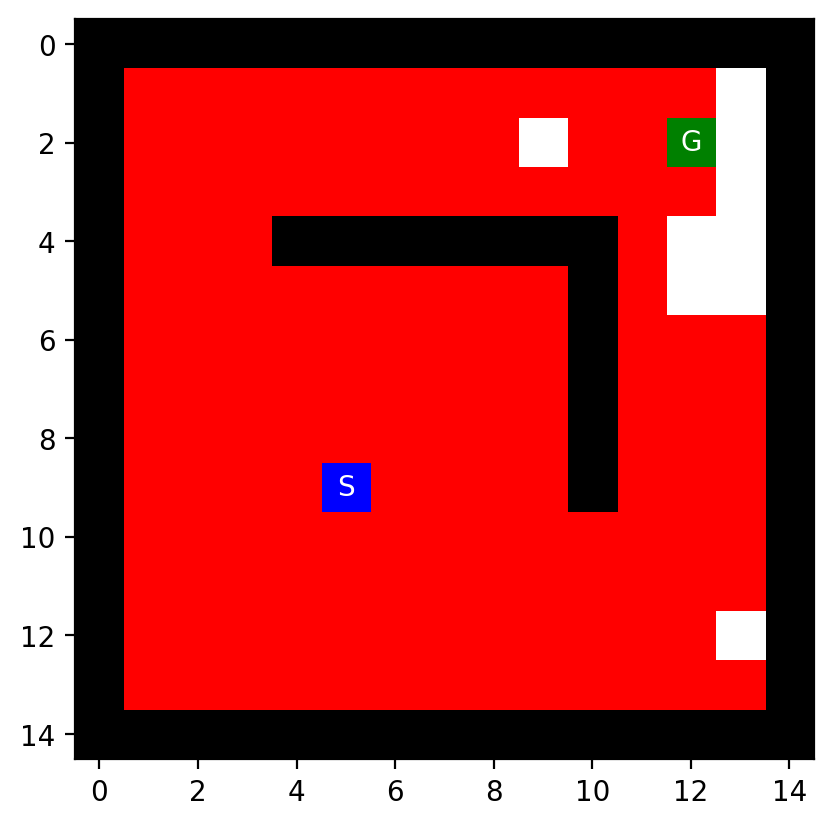

In [6]:
ts.set_order(random = True)

# run it multiple times to see the effect of randomization
for _ in range(5):
    %time result = ts.DFS(maze, check_cycle = False, max_tries = 100000, vis = False, debug_reached = True)

    #result
    ts.show_path(maze, result)
    if result['path'] is None:
        print("No solution found!")

### Run randomized DFS multiple times and use the best solution.

__Note:__ IDS takes a similar amount of time and memory, but is guaranteed optimal.

CPU times: user 3.69 s, sys: 63.1 ms, total: 3.75 s
Wall time: 3.75 s
Solutions have path_lengths of [70, 80, 52, 26, 74, 52, 36, 38, 68, 48, 90, 92, 44, 74, 80, 64, 82, 30, 64, 78, 62, 72, 74, 42, 64, 78, 58, 96, 54, 52, 34, 84, 72, 58, 52, 84, 24, 96, 96, 56, 100, 68, 80, 80, 66, 76, 36, 50, 28, 38, 78, 72, 76, 46, 64, 72, 78, 70, 62, 62, 64, 50, 72, 48, 74, 50, 82, 118, 60, 74, 86, 82, 76, 72, 64]
Path cost: 24 | Expanded: 47 | Max frontier: 39 | Max depth: 25
Actions: ESEEEESEENENNNNWNWNENWNE


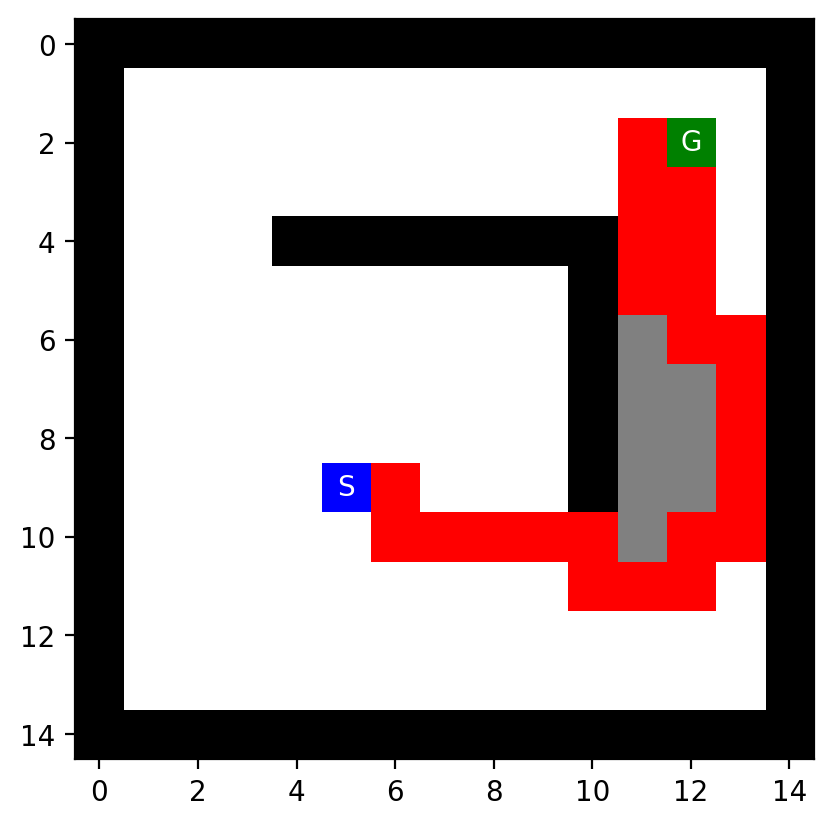

In [7]:
ts.set_order(random = True)

N = 100
%time results = [ ts.DFS(maze, max_tries = 10000, vis = False) for _ in range(N) ]

# check if we found a solution and display the best solution
results = [ r for r in results if not r['path'] is None ]
if len(results) > 0:
    path_lengths = [ len(r['path'])-1 for r in results ]

    print(f"Solutions have path_lengths of {path_lengths}")

    result = results[ts.min_index(path_lengths)]
    ts.show_path(maze, result)
else:
    print("No solution found!")

### Depth limited DFS

Note: The frontier needs to be checked differently during cycle checking!

In [8]:
ts.set_order(random = True)

%time result = ts.DFS(maze, limit = 5, frontier_option = 2, max_tries = 100000, vis = False, debug_reached = True)
ts.show_path(maze, result)

CPU times: user 1.34 ms, sys: 69 μs, total: 1.41 ms
Wall time: 1.42 ms
No solution found; expanded: 344 ; terminated at max_tries: False


### IDS

__Notes:__ 

* IDS with DFS does not store reached squares, so gray areas are not shown!

* IDS depends on the cycle checking of DFS and therefore is also affected by these problems.

CPU times: user 16.3 ms, sys: 0 ns, total: 16.3 ms
Wall time: 16.2 ms
Path cost: 16 | Expanded: 3418 | Max frontier: 23 | Max depth: 16
Actions: ESEEEEEENNNNNNNN


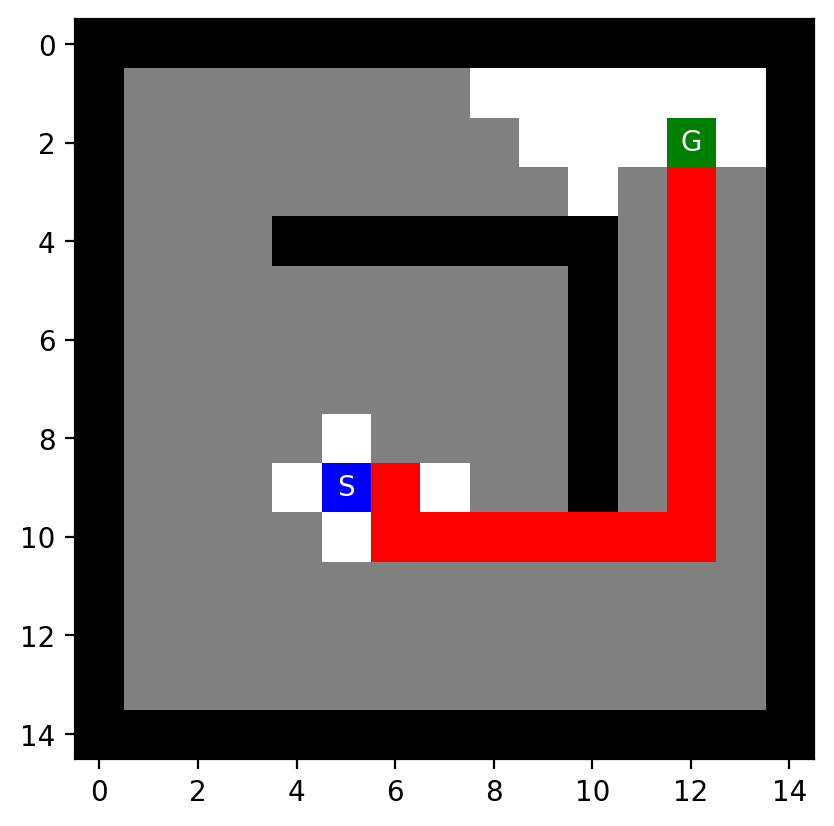

In [9]:
ts.set_order(random = True)

%time result = ts.IDS(maze, frontier_option = 2, max_tries = 100000)
ts.show_path(maze, result)

### Greedy Best-First Search (GBFS)

In [10]:
# set the heuristic to Manhattan distance
ts.heuristic = ts.manhattan

CPU times: user 600 μs, sys: 0 ns, total: 600 μs
Wall time: 604 μs
Path cost: 20 | Expanded: 39 | Max frontier: 29 | Max depth: 19
Actions: ENNEEESSSEENNENNNNNN


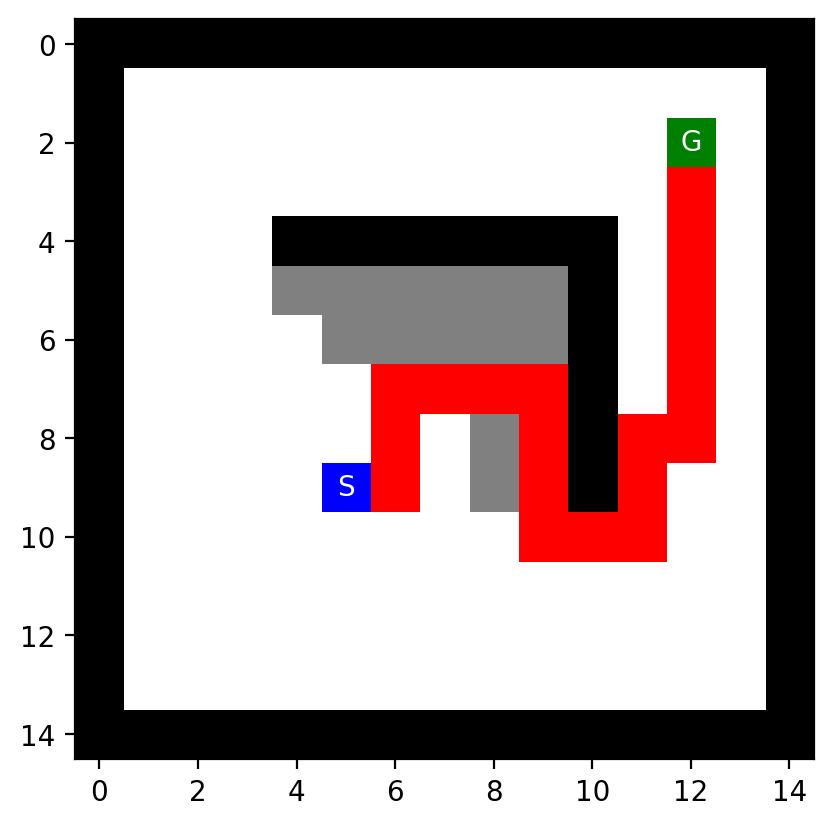

In [11]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "GBFS", debug = False, vis = False)
ts.show_path(maze, result)

### A* Search

CPU times: user 505 μs, sys: 26 μs, total: 531 μs
Wall time: 534 μs
Path cost: 16 | Expanded: 36 | Max frontier: 37 | Max depth: 15
Actions: EEEESEENNNENNNNN


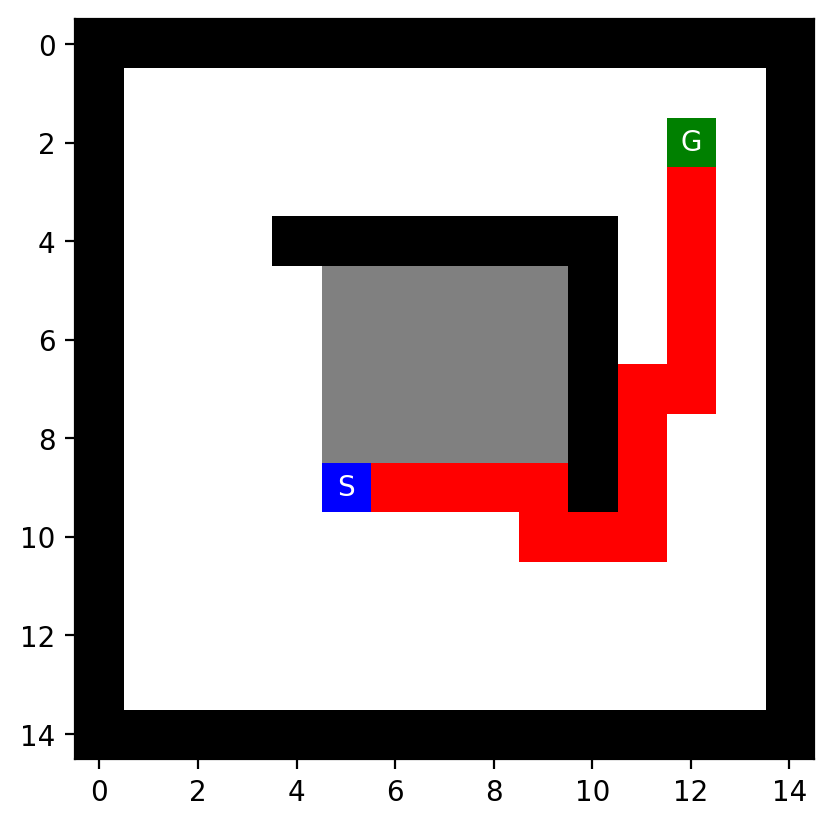

In [12]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", debug = False, vis = False)
ts.show_path(maze, result)

### Weighted A* Search

$W > 1$ tends towards GBFS (optimality is not guaranteed)

CPU times: user 467 μs, sys: 23 μs, total: 490 μs
Wall time: 494 μs
Path cost: 16 | Expanded: 36 | Max frontier: 32 | Max depth: 15
Actions: EEEESEEENNNNNNNN


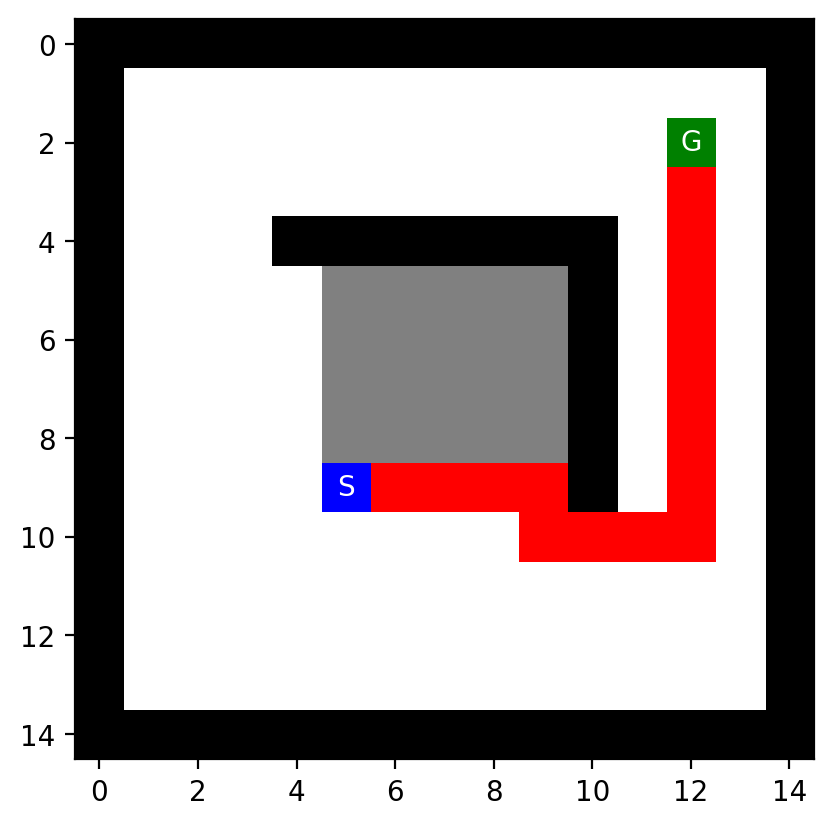

In [13]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", W = 1+1e-9, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: user 422 μs, sys: 21 μs, total: 443 μs
Wall time: 446 μs
Path cost: 16 | Expanded: 40 | Max frontier: 31 | Max depth: 15
Actions: EEEESEENENNNNNNN


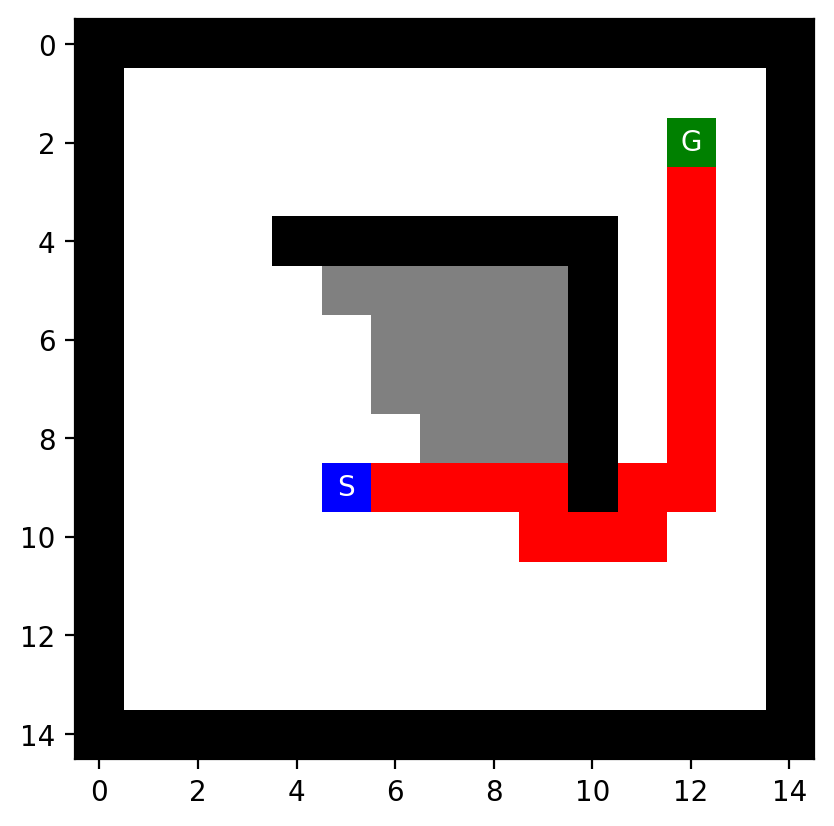

In [14]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 5, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: user 377 μs, sys: 0 ns, total: 377 μs
Wall time: 380 μs
Path cost: 16 | Expanded: 35 | Max frontier: 31 | Max depth: 15
Actions: EEEESEEENNNNNNNN


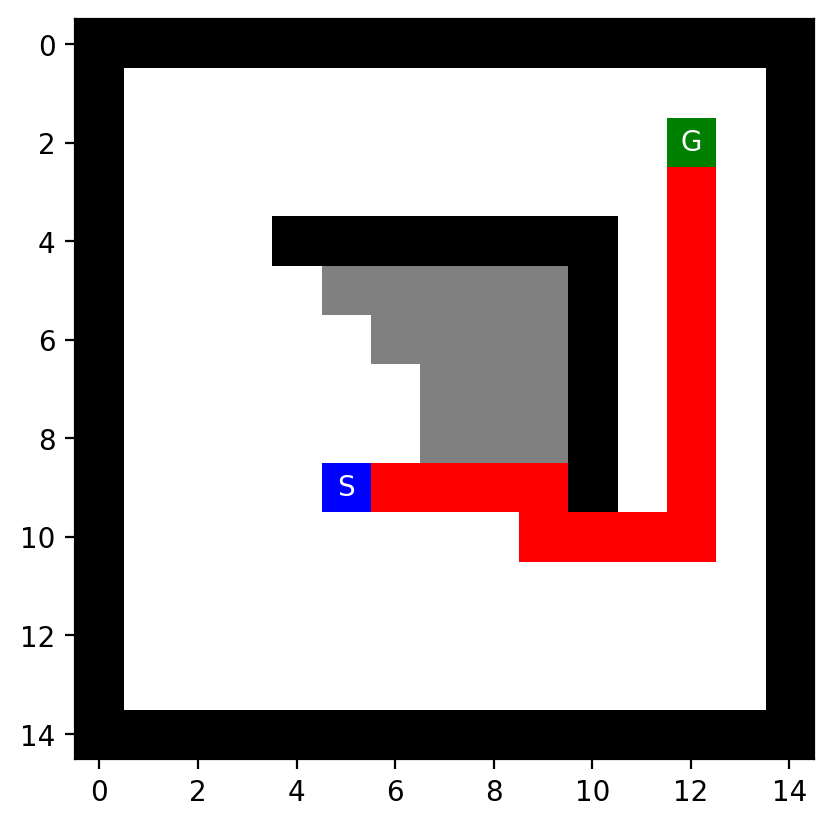

In [15]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 1000, debug = False, vis = False)
ts.show_path(maze, result)

$W<1$ tends towards Uniform-Cost Search/BFS (optimality is guaranteed)

CPU times: user 1.17 ms, sys: 0 ns, total: 1.17 ms
Wall time: 1.17 ms
Path cost: 16 | Expanded: 88 | Max frontier: 35 | Max depth: 15
Actions: EEEESEENNNNNNNNE


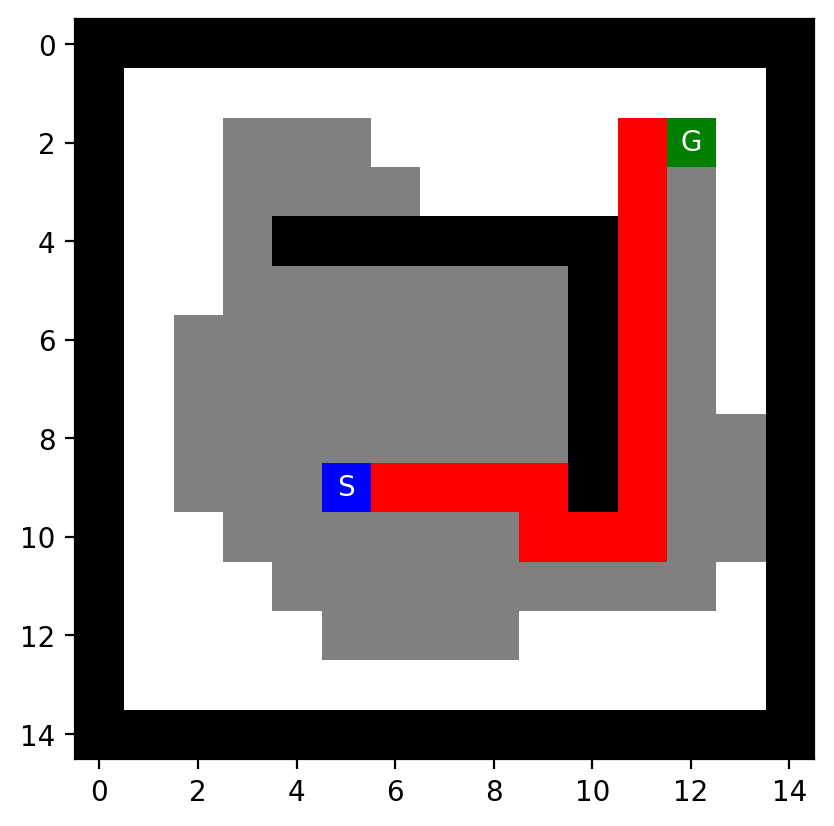

In [16]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .7, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: user 1.7 ms, sys: 0 ns, total: 1.7 ms
Wall time: 1.7 ms
Path cost: 16 | Expanded: 148 | Max frontier: 18 | Max depth: 15
Actions: EEEESEENNNNNNNEN


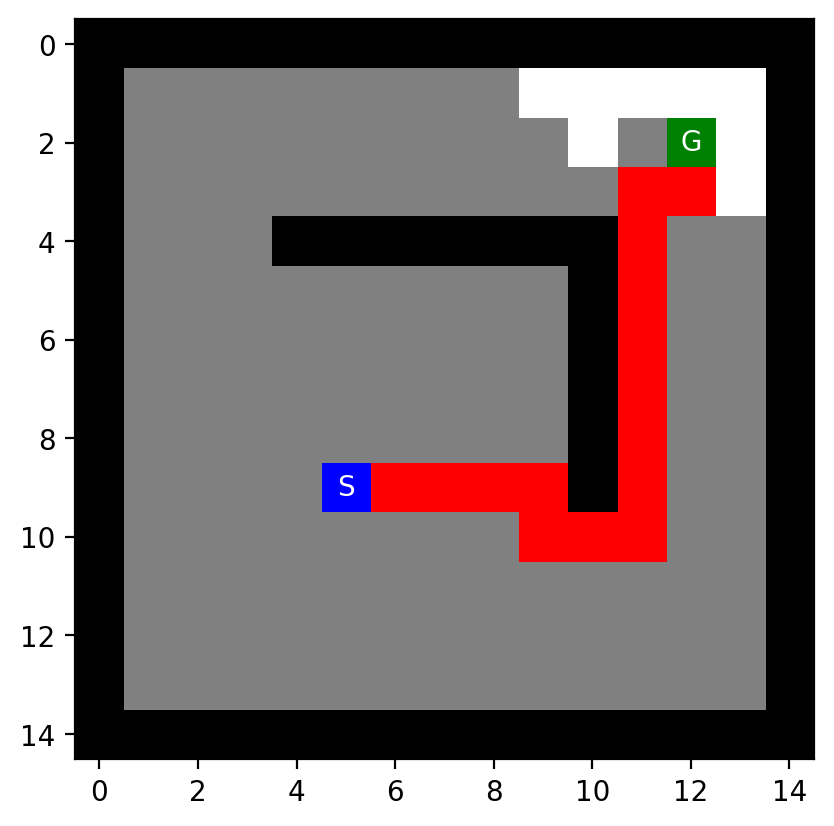

In [17]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .0001, debug = False, vis = False)
ts.show_path(maze, result)

### Compare Timing

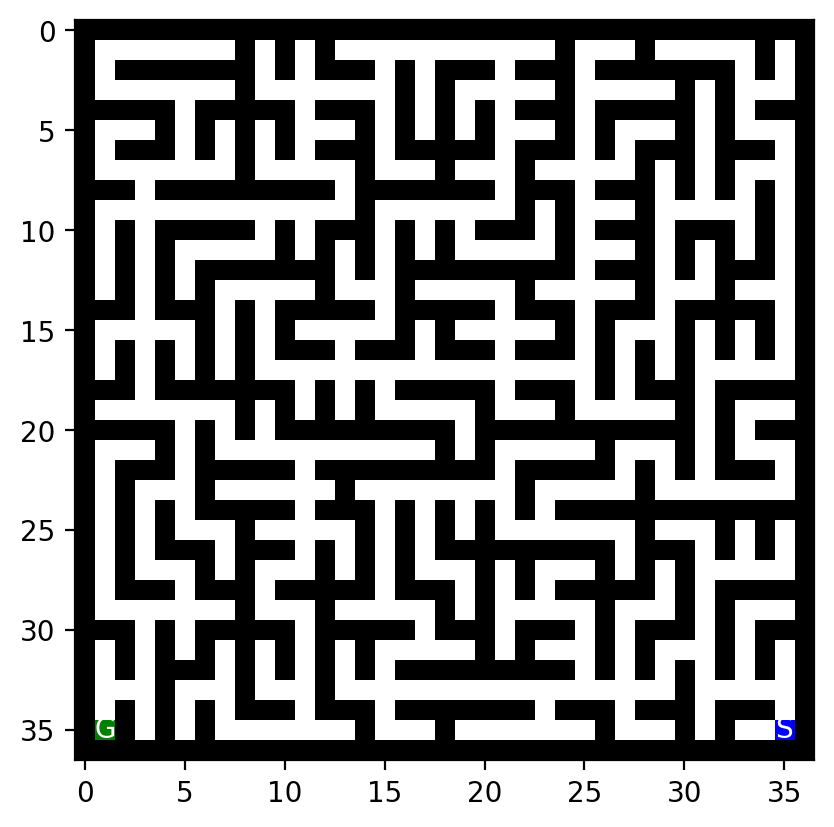

In [18]:
#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("L_maze.txt", "r")
#f = open("loops_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

ts.show_maze(maze)

ts.set_order(random=True)


In [19]:
import timeit
import math

reps = 10

times = {}

algorithms = ["BFS", "DFS", "GBFS", "A*"]

### FIXME: add IDS

for a in algorithms:
    times[a] = math.ceil(timeit.timeit(stmt = f'ts.best_first_search(maze, strategy = "{a}", debug = False, vis = False)', 
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)
    
times['DFS(no reached)'] = math.ceil(timeit.timeit(stmt = f'ts.DFS(maze, vis = False)', 
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)

times['IDS'] = math.ceil(timeit.timeit(stmt = f'ts.IDS(maze, vis = False)', 
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)

In [20]:
import pandas as pd
df = pd.DataFrame(times, index = ["time in micro seconds"])
df

,BFS,DFS,GBFS,A*,DFS(no reached),IDS
time in micro seconds,3101,2332,2939,4511,6514,282979


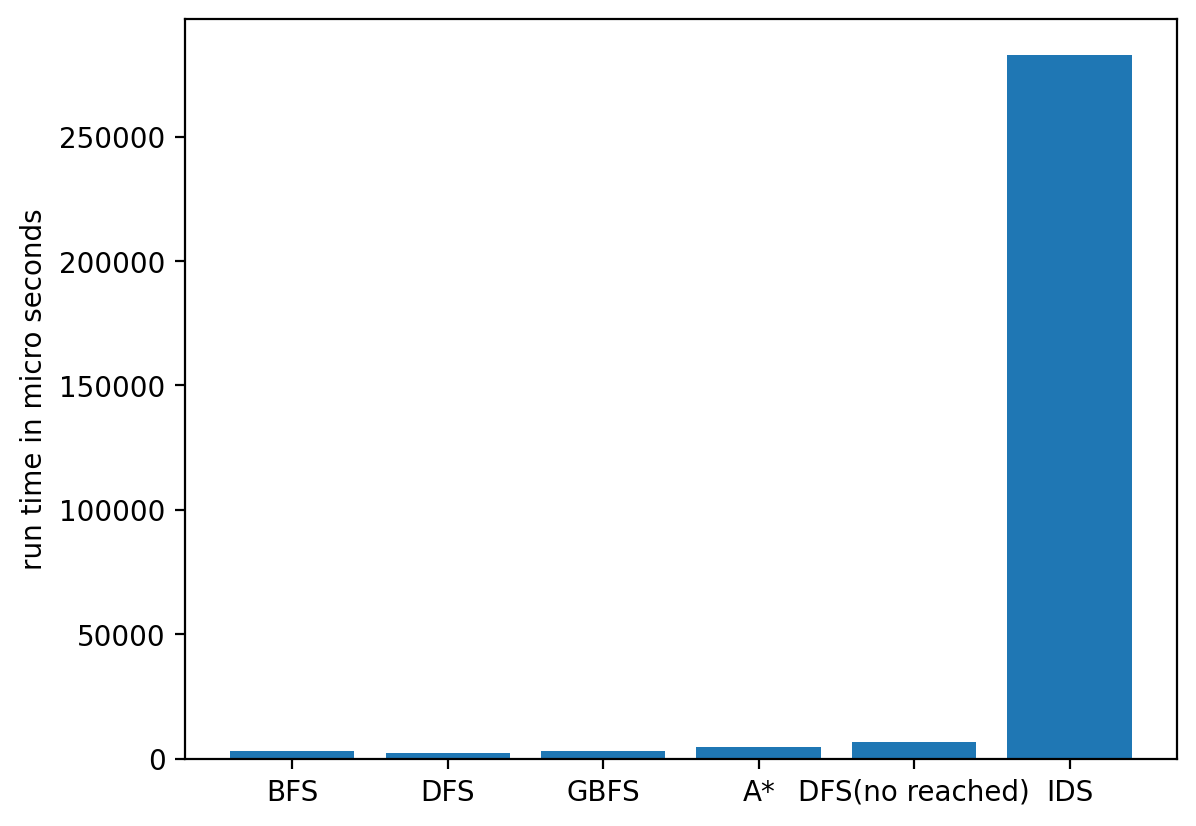

In [21]:
import matplotlib.pyplot as plt

plt.bar(df.columns, height = df.iloc[0])
plt.ylabel("run time in micro seconds")
plt.show()

---
# BÀI 3. TÌM KIẾM KHÔNG THÔNG TIN: BFS VÀ DFS

**Yêu cầu:** (1) Chạy BFS, theo dõi queue/frontier, số nút mở rộng và đường đi; (2) chạy DFS nhiều lần khi thứ tự sinh trạng thái ngẫu nhiên; (3) giải thích FIFO/LIFO, tính đầy đủ, tối ưu và bộ nhớ. 

> **Nguồn chương trình:** Các cell bên trên được giữ theo notebook gốc. Tệp `tree_search_solution.py` đi kèm là **bản cài đặt độc lập phục vụ bài thực hành**, nhằm thay thế module tác giả ghi là *not published*; không khẳng định là phiên bản chính thức. Phần dưới đặt dữ liệu `small_maze.txt` riêng để tránh biến `maze` đã bị đổi sang `large_maze.txt` ở mục Compare Timing.

**Quy ước đo lường:** `n_expanded` đếm những lần lấy nút khỏi frontier và **thực hiện mở rộng nút con** (không tính lần lấy đích ra để kiểm tra). `max_frontier` là số phần tử cực đại thực tế trong cấu trúc dữ liệu. DFS dùng **kiểm tra chu trình trên đường đi hiện tại**, tránh lặp vòng trong một nhánh nhưng có thể gặp lại cùng trạng thái ở nhánh khác.

## 3.1. Mô tả thuật toán BFS (Breadth-First Search)

BFS duy trì **Queue (FIFO)**, nghĩa là trạng thái được thêm trước sẽ được xét trước. Thuật toán bắt đầu tại ô `S`, lần lượt mở rộng các trạng thái theo độ sâu tăng dần cho đến khi lấy được trạng thái `G` từ queue. 

Các bước: (1) Thêm nút gốc vào queue; (2) lấy nút đầu queue; (3) nếu là `G`, truy hồi chuỗi hành động qua `parent`; (4) ngược lại, sinh các trạng thái hợp lệ và chưa phát hiện để thêm vào cuối queue; (5) tiếp tục cho đến khi tìm thấy đích hoặc queue rỗng.

Trong mỗi mê cung, di chuyển theo bốn hướng `N, E, S, W` có chi phí bước bằng 1, vì thế BFS tìm đường đi **ngắn nhất theo số bước**. Tập `reached` được sử dụng để không thêm cùng một trạng thái nhiều lần.

BFS - small_maze
Trạng thái bắt đầu: (np.int64(3), np.int64(11))
Trạng thái đích: (np.int64(8), np.int64(1))
Độ dài đường đi tối ưu: 19
Số nút được mở rộng: 92
Max frontier: 9
Dãy hành động: E -> E -> S -> S -> W -> S -> S -> W -> W -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W
Đường đi: [(np.int64(3), np.int64(11)), (np.int64(3), np.int64(12)), (np.int64(3), np.int64(13)), (np.int64(4), np.int64(13)), (np.int64(5), np.int64(13)), (np.int64(5), np.int64(12)), (np.int64(6), np.int64(12)), (np.int64(7), np.int64(12)), (np.int64(7), np.int64(11)), (np.int64(7), np.int64(10)), (np.int64(8), np.int64(10)), (np.int64(8), np.int64(9)), (np.int64(8), np.int64(8)), (np.int64(8), np.int64(7)), (np.int64(8), np.int64(6)), (np.int64(8), np.int64(5)), (np.int64(8), np.int64(4)), (np.int64(8), np.int64(3)), (np.int64(8), np.int64(2)), (np.int64(8), np.int64(1))]
Path cost: 19 | Expanded: 92 | Max frontier: 9 | Max depth: 19
Actions: EESSWSSWWSWWWWWWWWW


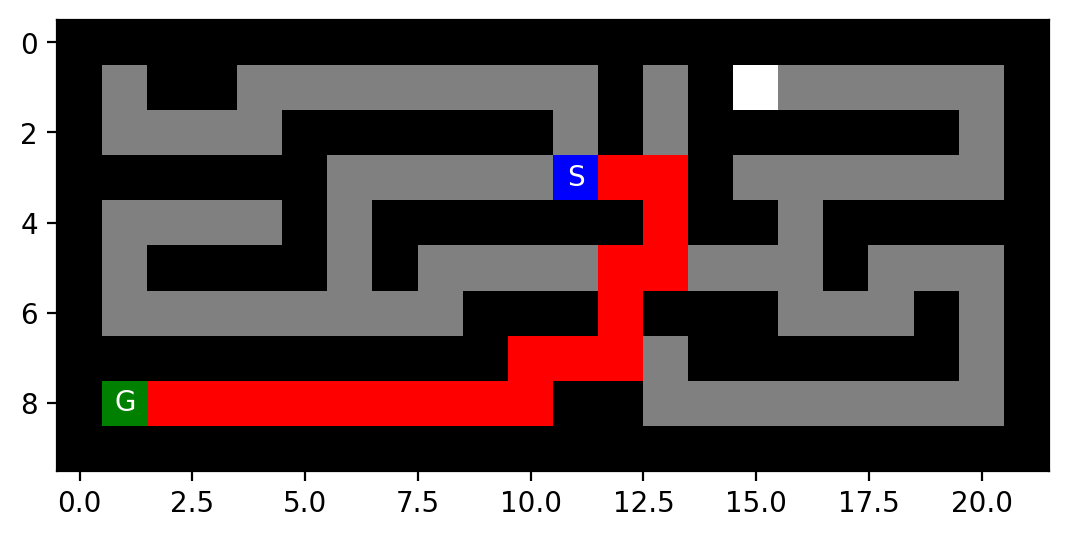

In [22]:
import tree_search_solution as ts
import maze_helper as mh
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

# Đọc dữ liệu trực tiếp; không sử dụng biến maze bị thay đổi từ các mục gốc.
with open('small_maze.txt', encoding='utf-8') as file:
    maze_bai3 = mh.parse_maze(file.read())

ts.set_order('NESW')
bfs_bai3 = ts.best_first_search(maze_bai3, strategy='BFS')
assert bfs_bai3['path'] is not None
assert len(bfs_bai3['actions']) == bfs_bai3['path_cost']
print('BFS - small_maze')
print('Trạng thái bắt đầu:', mh.find_pos(maze_bai3, 'S'))
print('Trạng thái đích:', mh.find_pos(maze_bai3, 'G'))
print('Độ dài đường đi tối ưu:', bfs_bai3['path_cost'])
print('Số nút được mở rộng:', bfs_bai3['n_expanded'])
print('Max frontier:', bfs_bai3['max_frontier'])
print('Dãy hành động:', ' -> '.join(bfs_bai3['actions']))
print('Đường đi:', bfs_bai3['path'])
ts.show_path(maze_bai3, bfs_bai3)

### Quan sát frontier của BFS

Ở từng bước, queue giữ các trạng thái đã phát hiện nhưng chưa mở rộng. Mỗi vòng lặp, phần tử đầu tiên được lấy ra, còn các nút con hợp lệ chưa được phát hiện được thêm vào cuối queue. Để dễ theo dõi, bảng dưới chỉ liệt kê tối đa 25 tọa độ đầu tiên của frontier tại mỗi bước. `frontier_size` mới là kích thước thực của toàn queue.

In [23]:
frontier_bfs = pd.DataFrame(bfs_bai3['trace'][:15])
frontier_bfs['frontier'] = frontier_bfs['frontier'].map(lambda xs: ', '.join(map(str, xs)))
display(frontier_bfs.rename(columns={
    'step':'Bước', 'expanded':'Trạng thái mở rộng',
    'frontier_size':'Kích thước frontier', 'frontier':'Các vị trí trong frontier (tối đa 25)'
}))
print('Tổng số trạng thái được mở rộng:', bfs_bai3['n_expanded'])
print('Số phần tử frontier lớn nhất:', bfs_bai3['max_frontier'])

,Bước,Trạng thái mở rộng,Kích thước frontier,Các vị trí trong frontier (tối đa 25)
0,1,"(3, 11)",3,"(np.int64(2), np.int64(11)), (np.int64(3), np...."
1,2,"(2, 11)",3,"(np.int64(3), np.int64(12)), (np.int64(3), np...."
2,3,"(3, 12)",3,"(np.int64(3), np.int64(10)), (np.int64(1), np...."
3,4,"(3, 10)",3,"(np.int64(1), np.int64(11)), (np.int64(3), np...."
4,5,"(1, 11)",3,"(np.int64(3), np.int64(13)), (np.int64(3), np...."
5,6,"(3, 13)",4,"(np.int64(3), np.int64(9)), (np.int64(1), np.i..."
6,7,"(3, 9)",4,"(np.int64(1), np.int64(10)), (np.int64(2), np...."
7,8,"(1, 10)",4,"(np.int64(2), np.int64(13)), (np.int64(4), np...."
8,9,"(2, 13)",4,"(np.int64(4), np.int64(13)), (np.int64(3), np...."
9,10,"(4, 13)",4,"(np.int64(3), np.int64(8)), (np.int64(1), np.i..."


Tổng số trạng thái được mở rộng: 92
Số phần tử frontier lớn nhất: 9


## 3.2. Khảo sát DFS (Depth-First Search)

DFS dùng **Stack (LIFO)**: trạng thái được thêm vào sau cùng sẽ được mở rộng trước. Do đó, thứ tự các hướng được **đẩy vào stack** có ảnh hưởng lớn tới thứ tự tìm kiếm thực tế (khi `set_order('NESW')`, phần tử `W` sẽ được ưu tiên lấy ra trước nếu hợp lệ).

Thực nghiệm thứ nhất giữ thứ tự hướng cố định. Thực nghiệm thứ hai đảo ngẫu nhiên thứ tự sinh con ở mỗi lần mở rộng. Mỗi lần thử đều sử dụng seed khác nhau nhưng công bố seed để tái lập kết quả. DFS có kiểm tra chu trình trên đường đi hiện tại và giới hạn số lần mở rộng nhằm tránh chạy quá lâu trong các không gian nhiều đường vòng.

DFS với thứ tự thêm nút NESW:
Path cost: 29
Nút mở rộng: 39
Max frontier: 5
Hành động: W -> W -> W -> W -> W -> S -> S -> S -> E -> E -> N -> E -> E -> E -> E -> S -> S -> W -> W -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W
Path cost: 29 | Expanded: 39 | Max frontier: 5 | Max depth: 28
Actions: WWWWWSSSEENEEEESSWWSWWWWWWWWW


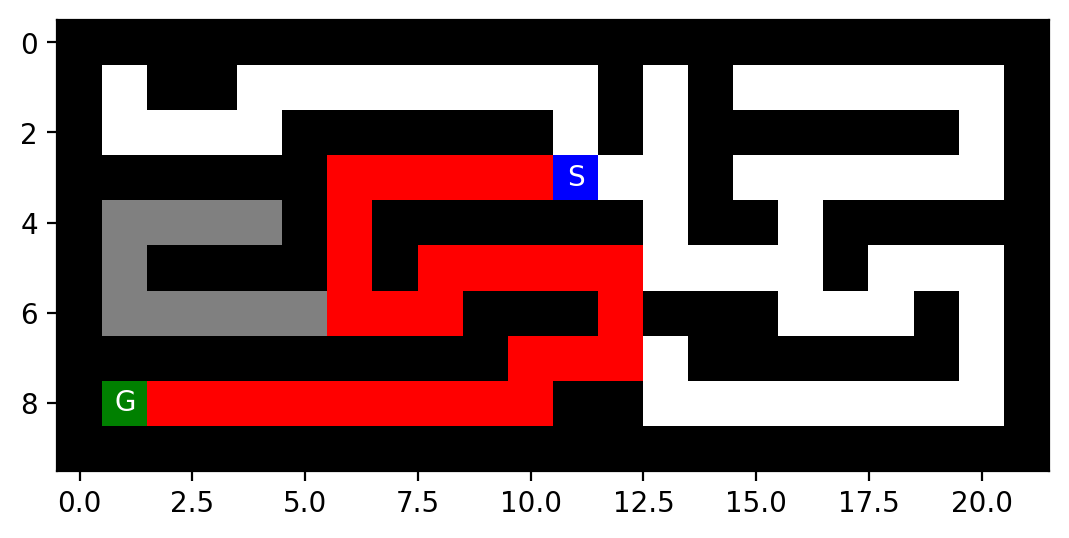

In [24]:
ts.set_order('NESW')
dfs_fixed = ts.DFS(maze_bai3, check_cycle=True, max_tries=30000)
print('DFS với thứ tự thêm nút NESW:')
print('Path cost:', dfs_fixed['path_cost'])
print('Nút mở rộng:', dfs_fixed['n_expanded'])
print('Max frontier:', dfs_fixed['max_frontier'])
print('Hành động:', ' -> '.join(dfs_fixed['actions']))
ts.show_path(maze_bai3, dfs_fixed)

In [25]:
n_runs = 8
rows = []
for trial in range(1, n_runs + 1):
    seed = 20261009 + trial
    random.seed(seed)
    ts.set_order(random=True)
    r = ts.DFS(maze_bai3, check_cycle=True, max_tries=30000)
    rows.append({
        'Lần chạy': trial, 'Seed': seed,
        'Đường đi (bước)': r['path_cost'],
        'Nút mở rộng': r['n_expanded'],
        'Max frontier': r['max_frontier'],
        'Tìm được đích': r['path'] is not None,
    })
dfs_trials = pd.DataFrame(rows)
display(dfs_trials)
print('Số lần tìm được đường:', int(dfs_trials['Tìm được đích'].sum()), '/', n_runs)
print('Độ dài đường đi BFS:', bfs_bai3['path_cost'])
print('Các độ dài đường đi DFS:', dfs_trials['Đường đi (bước)'].tolist())

,Lần chạy,Seed,Đường đi (bước),Nút mở rộng,Max frontier,Tìm được đích
0,1,20261010,49,73,6,True
1,2,20261011,49,65,6,True
2,3,20261012,49,65,6,True
3,4,20261013,49,65,6,True
4,5,20261014,37,37,7,True
5,6,20261015,37,79,6,True
6,7,20261016,19,45,6,True
7,8,20261017,19,35,5,True


Số lần tìm được đường: 8 / 8
Độ dài đường đi BFS: 19
Các độ dài đường đi DFS: [49, 49, 49, 49, 37, 37, 19, 19]


### Thí nghiệm bổ sung: cùng thuật toán trên các mê cung khác nhau

Để kiểm tra kết luận không phụ thuộc riêng một mê cung, sử dụng `small_maze`, `medium_maze` và `L_maze`. Trong so sánh này BFS có thứ tự cố định, DFS cũng có thứ tự cố định (`NESW`), tránh trộn yếu tố ngẫu nhiên khi đối chiếu độ dài đường đi. Đây là một thí nghiệm bổ sung cho Bài 3, không phải bảng so sánh toàn bộ thuật toán của Bài 8.

,Mê cung,Thuật toán,Path cost,Nút mở rộng,Max frontier,Max depth,Tìm được đường
0,small,BFS,19,92,9,19,True
1,small,DFS,29,39,5,28,True
2,medium,BFS,68,269,9,68,True
3,medium,DFS,152,153,8,151,True
4,L,BFS,16,151,17,16,True
5,L,DFS,122,132,109,121,True


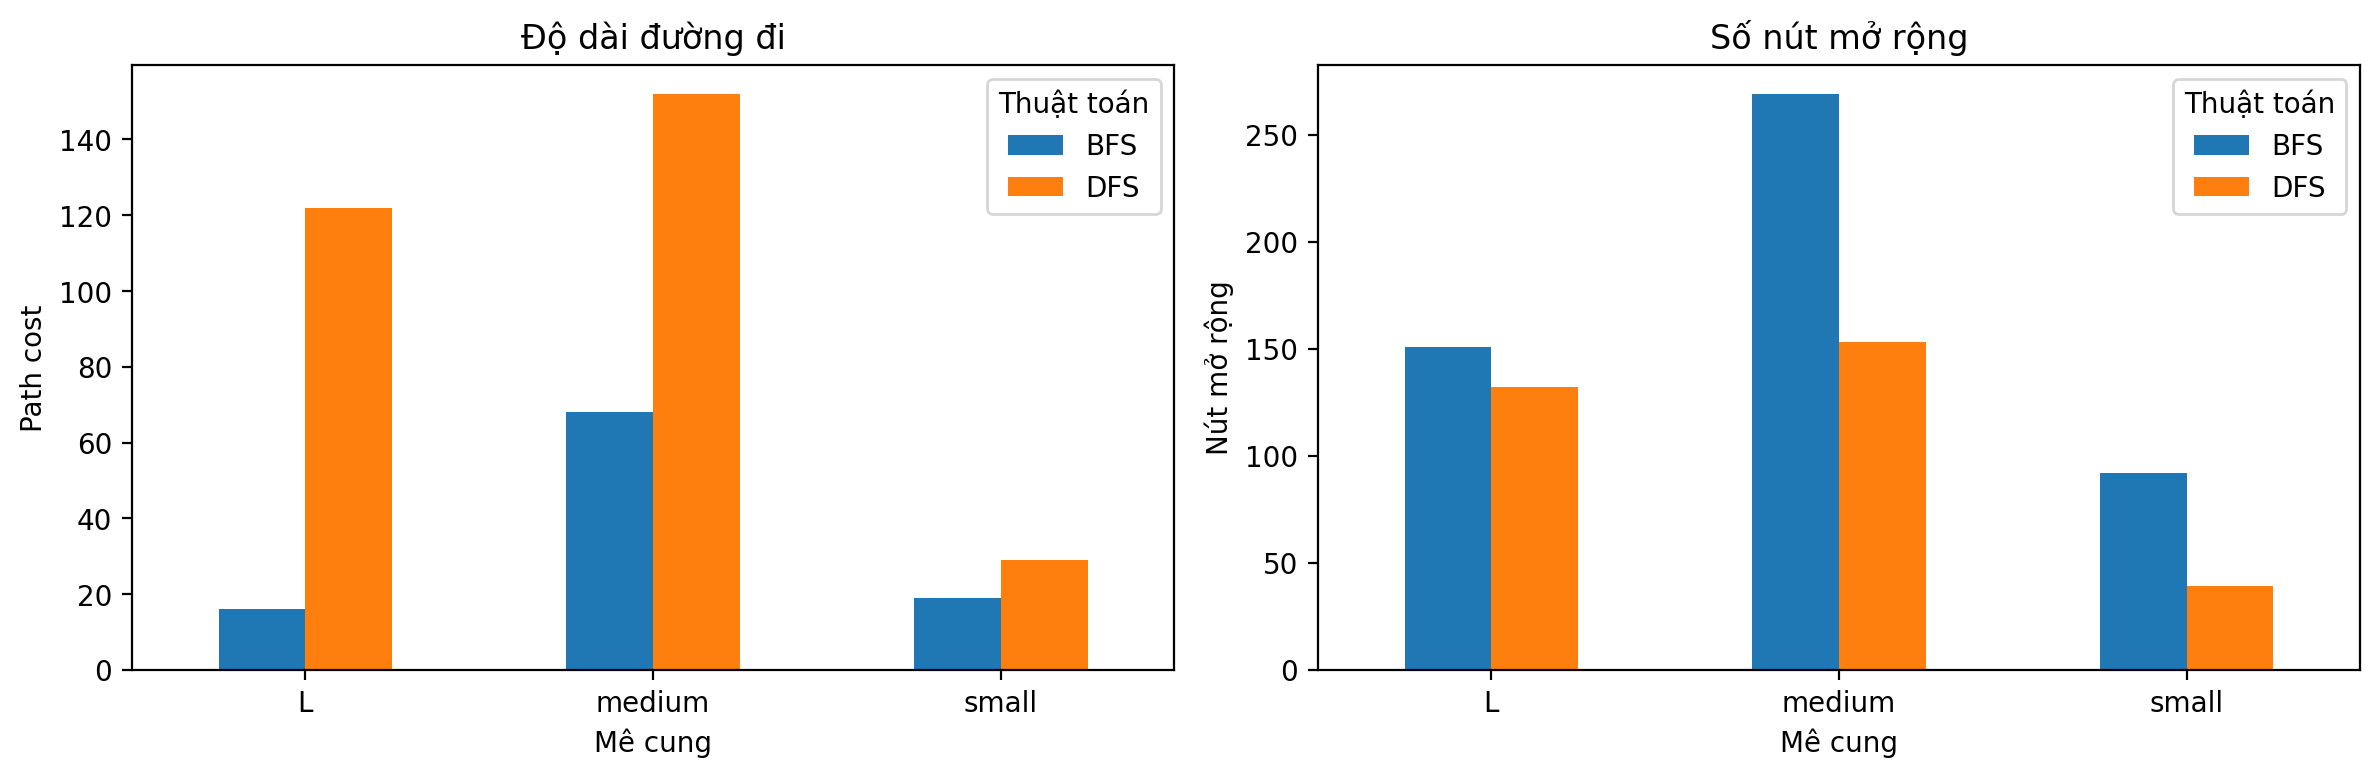

In [26]:
compare = []
for maze_name in ('small', 'medium', 'L'):
    with open(f'{maze_name}_maze.txt', encoding='utf-8') as f:
        maze_case = mh.parse_maze(f.read())
    ts.set_order('NESW')
    for algorithm in ('BFS', 'DFS'):
        r = (ts.best_first_search(maze_case, strategy='BFS') if algorithm == 'BFS'
             else ts.DFS(maze_case, check_cycle=True, max_tries=30000))
        compare.append({'Mê cung':maze_name, 'Thuật toán':algorithm,
                        'Path cost':r['path_cost'], 'Nút mở rộng':r['n_expanded'],
                        'Max frontier':r['max_frontier'], 'Max depth':r['max_depth'],
                        'Tìm được đường':r['path'] is not None})
compare_bai3 = pd.DataFrame(compare)
display(compare_bai3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, value, title in zip(axes, ('Path cost', 'Nút mở rộng'),
                            ('Độ dài đường đi', 'Số nút mở rộng')):
    pivot = compare_bai3.pivot(index='Mê cung', columns='Thuật toán', values=value)
    pivot.plot.bar(ax=ax, rot=0, title=title)
    ax.set_ylabel(value)
plt.tight_layout()
plt.show()

## 3.3. So sánh BFS và DFS về mặt lý thuyết

| Tiêu chí | BFS | DFS |
|---|---|---|
| Frontier | Queue — **FIFO** | Stack — **LIFO** |
| Quy tắc ưu tiên | Nút ở độ sâu nhỏ hơn được xét trước | Đi sâu vào một nhánh trước khi quay lui |
| Tính đầy đủ | Có khi hệ số phân nhánh hữu hạn và tồn tại lời giải ở độ sâu hữu hạn (với phát hiện trạng thái lặp phù hợp) | **Không bảo đảm** trong không gian vô hạn/có chu trình; với mê cung hữu hạn và kiểm tra chu trình đầy đủ, có thể tìm thấy lời giải nếu không cắt bởi `max_tries` |
| Tính tối ưu | Có khi mỗi bước chi phí bằng nhau | Không bảo đảm |
| Bộ nhớ | Có thể cần lưu nhiều nút của cùng một tầng; theo tree search thường $O(b^d)$ | DFS theo đường đi với cycle checking cần bộ nhớ theo độ sâu và số nhánh, thường khoảng $O(bm)$; kết quả phụ thuộc cách quản lý frontier |

Với $b$ là hệ số phân nhánh, $d$ là độ sâu lời giải nông nhất, $m$ là độ sâu tối đa của đường tìm kiếm. Độ phức tạp này là **ước lượng lý thuyết theo mô hình triển khai**, không phải số đo trực tiếp từ bảng thực nghiệm.

## 3.4. Nhận xét và kết luận

**Nhận xét kết quả:** Với `small_maze.txt`, BFS cho độ dài đường đi bằng **19 bước** (mỗi bước có chi phí 1). DFS với thứ tự hướng thêm `NESW` cho đường đi **29 bước**, vì thuật toán ưu tiên đi sâu và không bắt buộc phát hiện đường đi nông nhất trước. Khi thay đổi thứ tự sinh trạng thái con bằng cơ chế ngẫu nhiên, số nút mở rộng, độ dài đường đi và frontier cũng có thể thay đổi; kết quả cụ thể được ghi trong bảng thực nghiệm bên trên.

**Kết luận:** BFS phù hợp khi cần đường đi ngắn nhất trong lưới có chi phí bước đồng nhất, đổi lại có thể sử dụng nhiều bộ nhớ hơn. DFS thường tiết kiệm bộ nhớ hơn trong cách cài đặt theo đường đi, nhưng có thể tìm được lời giải dài và nhạy cảm với thứ tự sinh trạng thái con. Cần có kiểm tra chu trình và/hoặc giới hạn số lần mở rộng để tránh chạy quá lâu trên bài toán nhiều vòng lặp. Kết quả một số lần chạy DFS **không phải** bằng chứng rằng DFS luôn không tối ưu: điều quan trọng là DFS *không bảo đảm* tối ưu.

**Ghi chú:** Các con số ở mục trên được tính bởi bản cài đặt độc lập kèm theo, không được diễn giải là đầu ra gốc của `tree_search_solution.py` chưa được công bố.